# Workflow-specific AI model selection

CEE/ENGMT 5980 preliminary case analysis. This notebook uses a frozen public BFCL snapshot; it does not call any model API. All weights and requirements are illustrative, not elicited stakeholder preferences. Run from the project folder. See README.md for assumptions and references.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
import importlib.util
project = Path.cwd()
assert (project / 'analysis.py').exists(), 'Run this notebook from its project folder'
spec = importlib.util.spec_from_file_location('project_analysis', project / 'analysis.py')
analysis = importlib.util.module_from_spec(spec)
spec.loader.exec_module(analysis)

In [2]:
summary = analysis.run()

{
  "raw": 109,
  "eligible": 66,
  "workflows": {
    "structured": {
      "pareto_count": 30,
      "profile_winners": {
        "balanced": [
          "xLAM-2-32b-fc-r (FC)"
        ],
        "quality_focused": [
          "Hammer2.1-3b (FC)"
        ],
        "resource_focused": [
          "Gemini-2.5-Flash-Lite (FC)"
        ]
      },
      "illustrative_screen_feasible_count": 14,
      "illustrative_screen_winners": [
        "Gemini-2.5-Flash (FC)"
      ]
    },
    "clarification": {
      "pareto_count": 22,
      "profile_winners": {
        "balanced": [
          "xLAM-2-32b-fc-r (FC)"
        ],
        "quality_focused": [
          "xLAM-2-70b-fc-r (FC)"
        ],
        "resource_focused": [
          "xLAM-2-32b-fc-r (FC)"
        ]
      },
      "illustrative_screen_feasible_count": 0,
      "illustrative_screen_winners": []
    }
  },
  "weight_vectors_per_workflow": 1771,
  "verification": "all checks passed"
}


## Data provenance and eligible configurations

Original configurations are not independent samples of a population. Exclusions are recorded in results/eligibility_audit.csv. All configuration identities include the reported tool-calling mode.

In [3]:
display(pd.read_csv(project / 'data' / 'eligible_configurations.csv').head(10))
print('Frozen input SHA256:', summary['source_sha256'])
print('Resource scale anchors:', summary['resource_value_anchors'])

,model,overall,structured,clarification,avoidance,benchmark_cost,p95_latency
0,Claude-Opus-4-5-20251101 (FC),77.47,76.83,58.0,84.72,86.55,7.56
1,Claude-Sonnet-4-5-20250929 (FC),73.24,72.58,52.5,86.61,43.73,7.27
2,Grok-4-1-fast-reasoning (FC),69.57,77.58,43.0,79.43,17.26,17.57
3,Claude-Haiku-4-5-20251001 (FC),68.70,71.00,52.5,85.11,14.23,3.15
4,Gemini-3-Pro-Preview (FC),68.14,75.50,56.5,77.85,224.69,58.48
5,Grok-4-0709 (FC),61.38,73.50,28.5,75.40,355.17,44.28
6,Moonshotai-Kimi-K2-Instruct (FC),59.06,69.42,44.5,87.34,6.19,13.78
7,Grok-4-1-fast-non-reasoning (FC),58.29,76.00,37.5,74.09,16.27,5.34
8,Command A Reasoning (FC),57.06,73.58,49.5,86.75,3.04,8.39
9,Gemini-2.5-Flash (FC),56.24,74.33,32.0,93.67,26.36,5.62


Frozen input SHA256: ede5081a24bc5ac7f9b3b09a52af6bcfcd35aa0f1709239fed979db77a8159a6
Resource scale anchors: {'benchmark_cost': [0.46, 355.17], 'p95_latency': [0.96, 568.59]}


## Preliminary scenario comparisons

The same profile weights are applied to each workflow so a change of task category can be distinguished from a change of preferences. The profiles are hypothetical design assumptions. Cost and latency refer to the entire benchmark, not the proposed application.

In [4]:
for workflow in analysis.WORKFLOWS:
    print(workflow, summary['workflows'][workflow])
    table = pd.read_csv(project / 'results' / f'{workflow}_consequence_and_rankings.csv')
    display(table[['model', workflow, 'avoidance', 'benchmark_cost', 'p95_latency', 'pareto', 'value_balanced']].head(6))

structured {'pareto_count': 30, 'profile_winners': {'balanced': ['xLAM-2-32b-fc-r (FC)'], 'quality_focused': ['Hammer2.1-3b (FC)'], 'resource_focused': ['Gemini-2.5-Flash-Lite (FC)']}, 'illustrative_screen_feasible_count': 14, 'illustrative_screen_winners': ['Gemini-2.5-Flash (FC)']}


,model,structured,avoidance,benchmark_cost,p95_latency,pareto,value_balanced
0,xLAM-2-32b-fc-r (FC),80.42,80.23,6.00,17.66,True,0.873132
1,Gemini-2.5-Flash (FC),74.33,93.67,26.36,5.62,True,0.868415
2,Hammer2.1-3b (FC),79.33,86.12,10.89,47.44,True,0.867302
3,Gemini-2.5-Flash-Lite (FC),70.92,92.50,7.55,1.67,True,0.864432
4,Command A Reasoning (FC),73.58,86.75,3.04,8.39,True,0.863747
5,Hammer2.1-7b (FC),72.50,90.12,4.99,31.26,True,0.857010


clarification {'pareto_count': 22, 'profile_winners': {'balanced': ['xLAM-2-32b-fc-r (FC)'], 'quality_focused': ['xLAM-2-70b-fc-r (FC)'], 'resource_focused': ['xLAM-2-32b-fc-r (FC)']}, 'illustrative_screen_feasible_count': 0, 'illustrative_screen_winners': []}


,model,clarification,avoidance,benchmark_cost,p95_latency,pareto,value_balanced
0,xLAM-2-32b-fc-r (FC),67.5,80.23,6.00,17.66,True,0.821452
1,xLAM-2-70b-fc-r (FC),74.0,79.11,25.10,91.21,True,0.808528
2,Claude-Haiku-4-5-20251001 (FC),52.5,85.11,14.23,3.15,True,0.771684
3,Command A Reasoning (FC),49.5,86.75,3.04,8.39,True,0.767427
4,Claude-Sonnet-4-5-20250929 (FC),52.5,86.61,43.73,7.27,True,0.756599
5,xLAM-2-3b-fc-r (FC),57.5,63.45,3.36,8.79,True,0.752506


## Completed figures

Pareto membership uses four objectives; the first image is a projection, not a two-objective frontier. Preference-grid shares are conditional on a specified grid, not deployment-success probabilities. Thresholds are assumptions and empty feasible sets are retained as results.

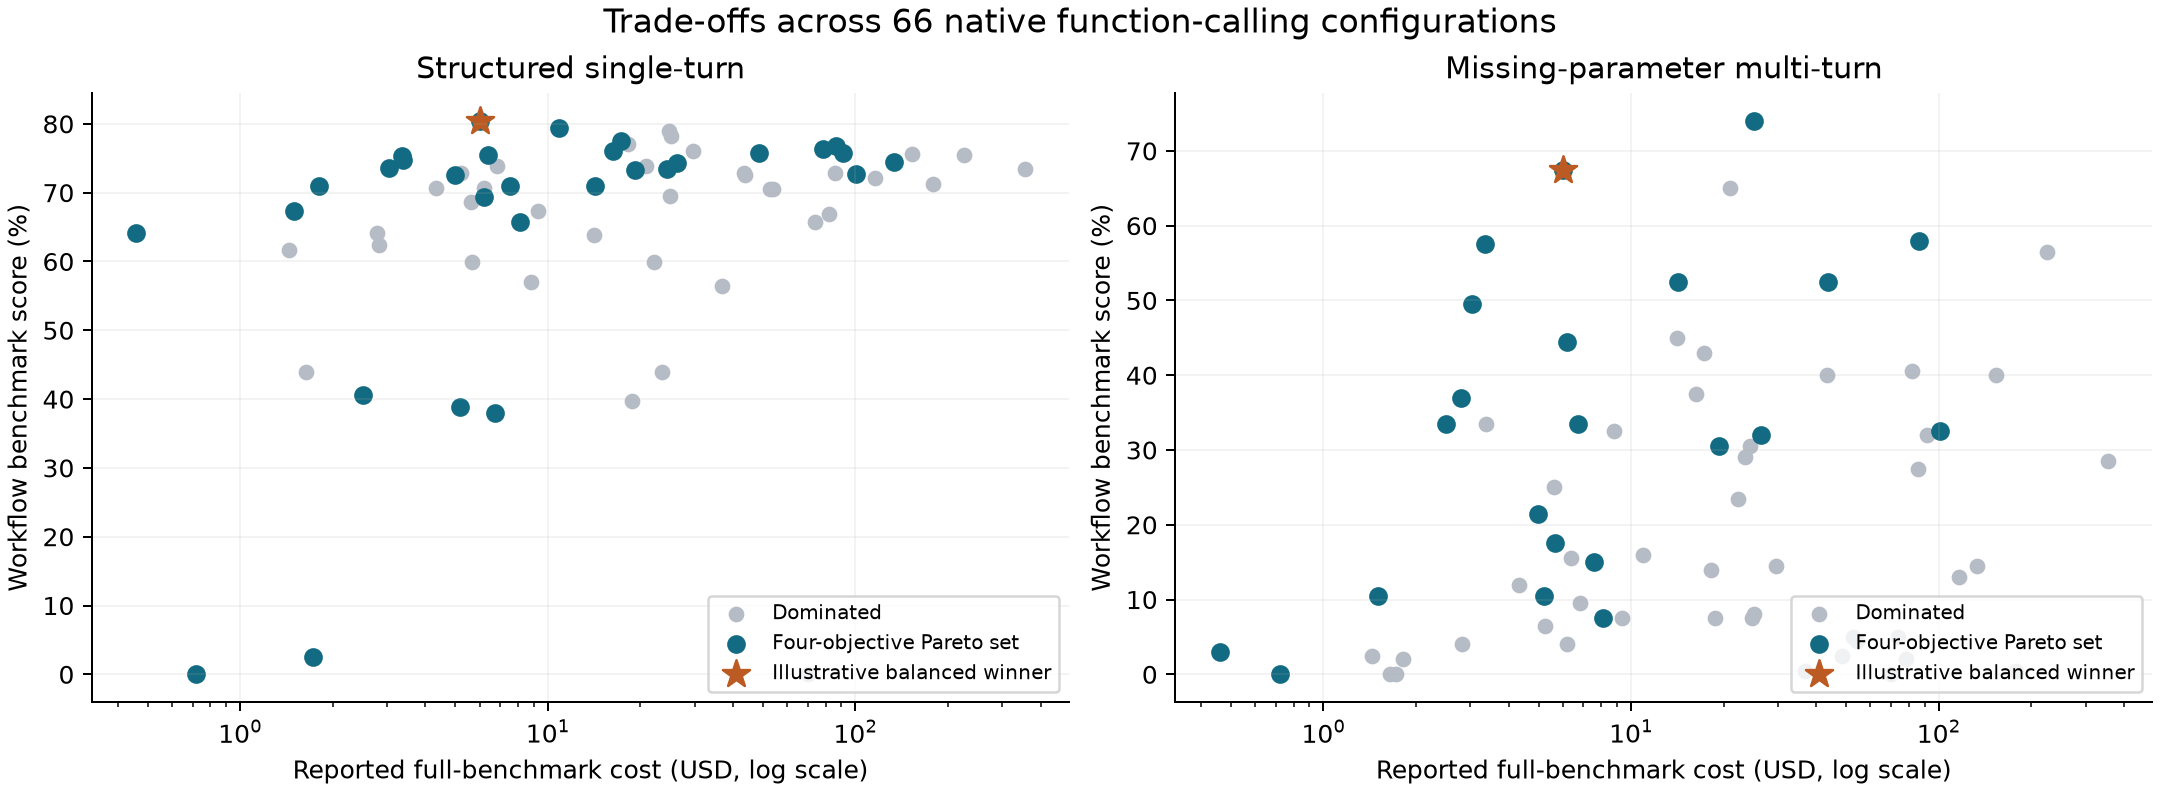

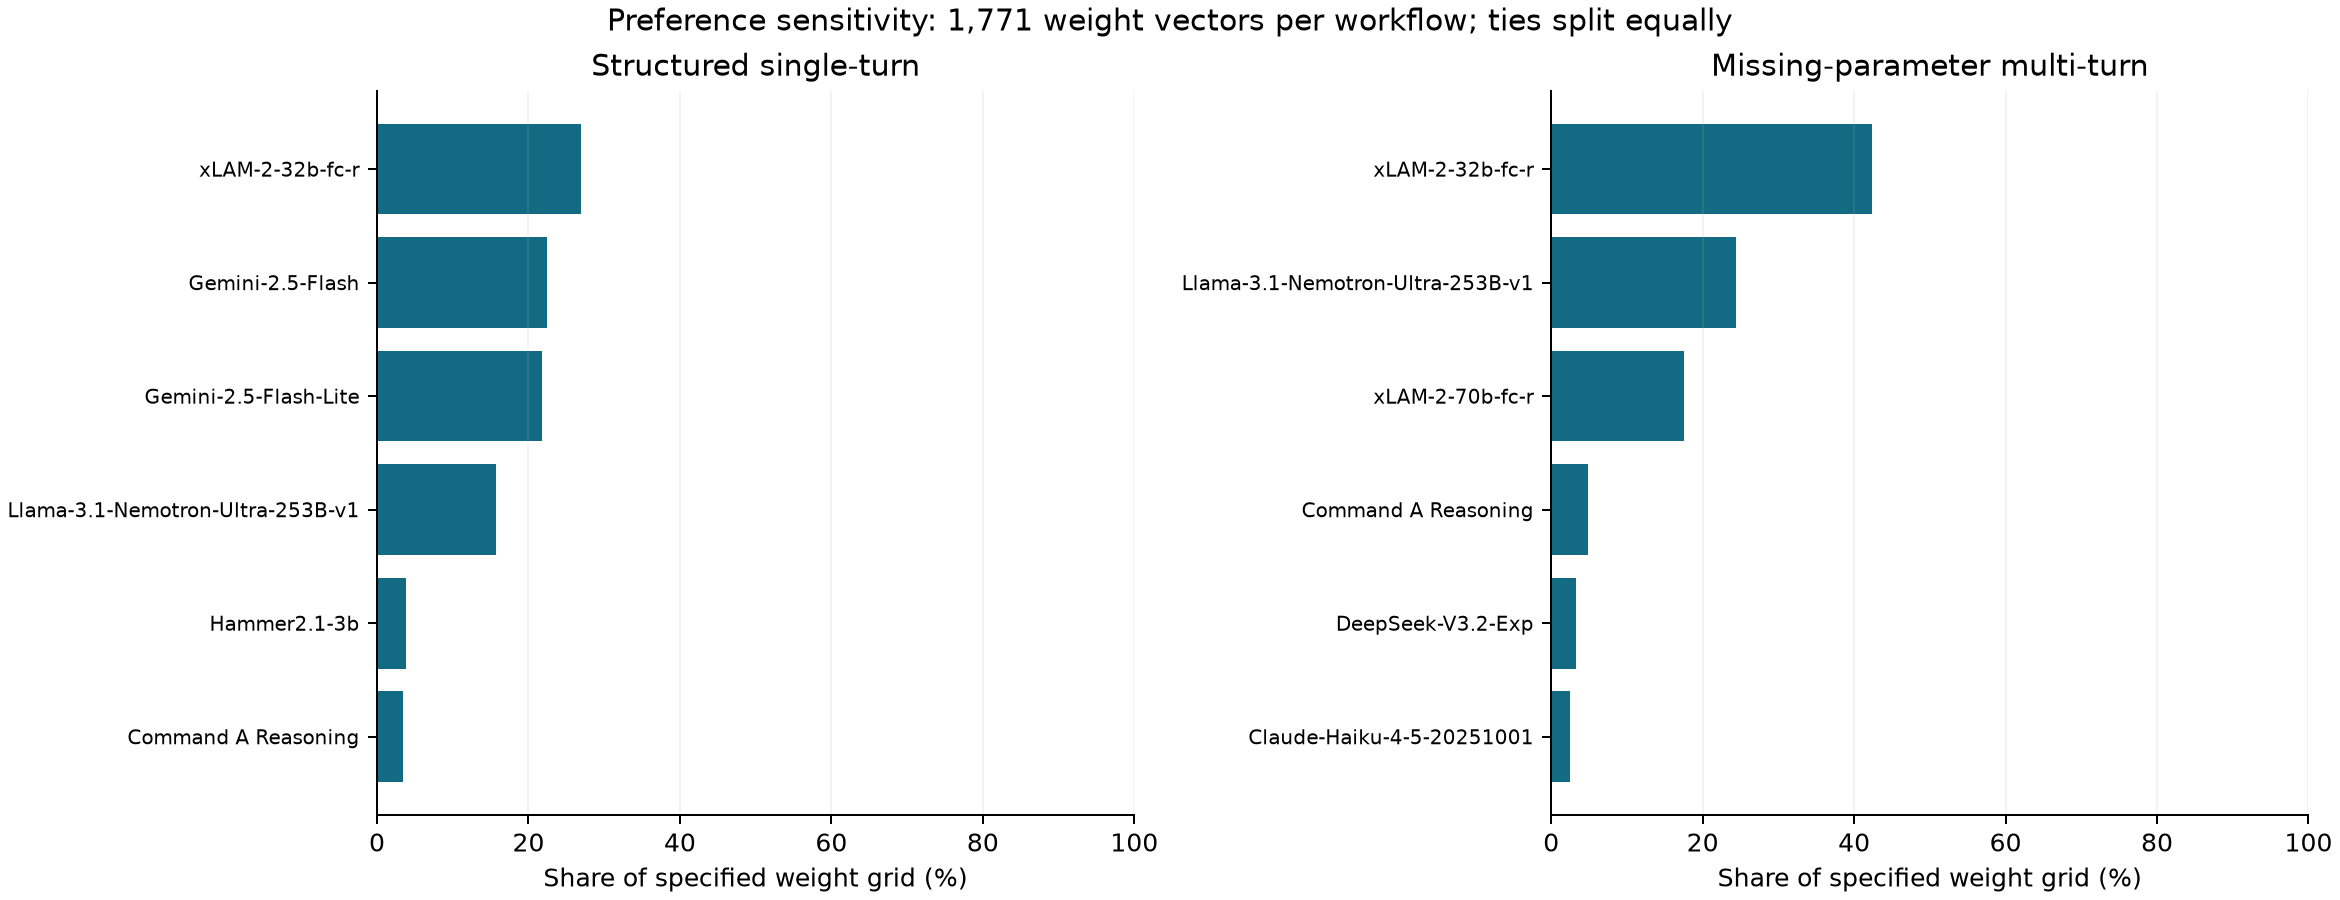

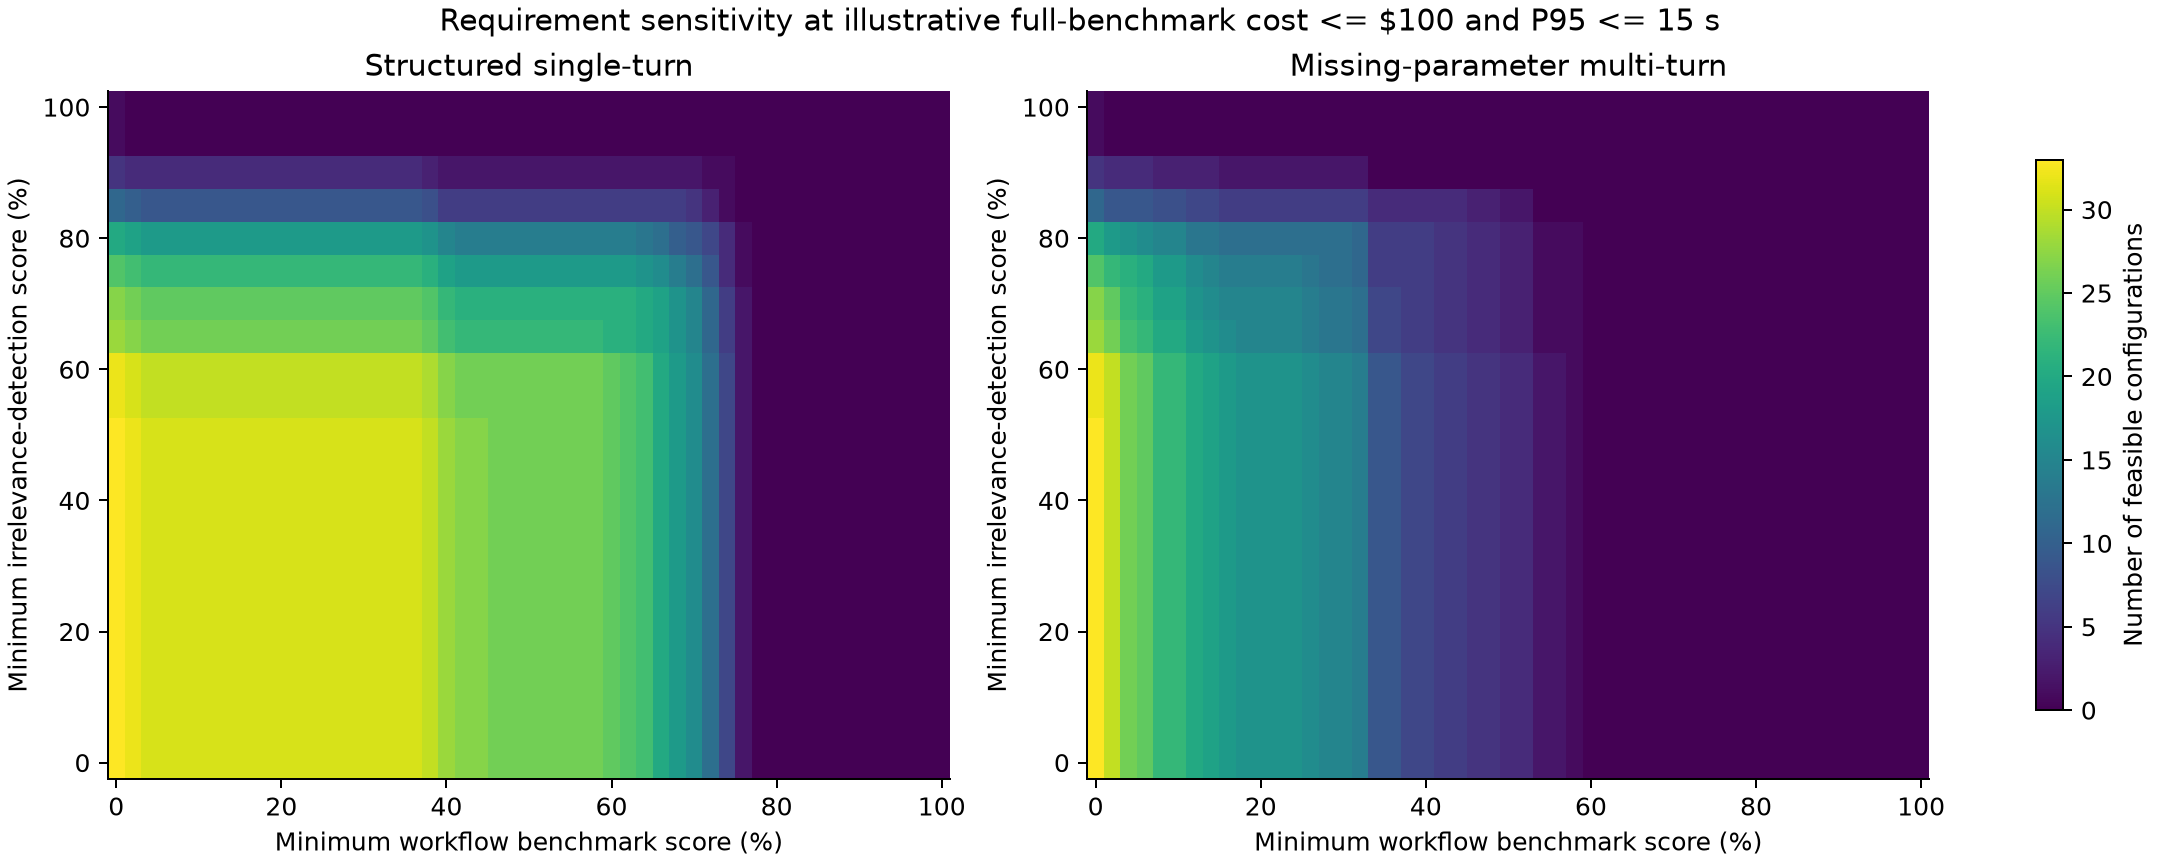

In [5]:
for name in ['01_pareto_tradeoffs.png', '02_preference_sensitivity.png', '03_requirement_sensitivity.png']:
    display(Image(filename=str(project / 'figures' / name)))

## Remaining decision-framing work

Record each group member's actual values and priorities before presenting revised rankings. Review trade-offs together; explain and log any amendments to objectives, thresholds, or candidate eligibility. Hold data and value-scale anchors fixed when isolating effects of feedback. Verify metric comparability and model availability before a final shortlist. Do not infer enterprise preferences, causal effects of model age, stochastic output reliability, or deployment readiness from this snapshot.

In [6]:
print(json.dumps(summary['verification'], indent=2))
print(*summary['limitations'], sep=chr(10))

{
  "input_hash": "passed",
  "pareto_direction_and_duplicate_checks": "passed",
  "positive_weight_winners_nondominated": "passed",
  "selection_shares_sum_to_one": "passed",
  "manual_score_spot_check": "passed"
}
Snapshot screening, not confirmation of current endpoint availability.
All weights and thresholds are illustrative; no group elicitation has occurred.
Benchmark-wide cost and P95 latency are not workflow-specific operating metrics.
Benchmark accuracy is not deployment success probability or output determinism.
Selection share depends on the specified preference grid and tie handling; it is not empirical probability.
Linear resource scales use observed eligible-set anchors and are sensitive to range/outliers.
